## Obteniendo género

In [1]:
import pandas as pd
import numpy as np

# 1. Cargar el dataset externo (ajusta el nombre/extensión si es necesario)
try:
    df_respuestas = pd.read_csv('respuestas.csv')
    df_amor = pd.read_csv('datos_limpios.csv')
    df_musica = pd.read_csv('datos_limpios_musica.csv')
except FileNotFoundError:
    df_respuestas = pd.read_excel('respuestas.xlsx') # Fallback por si es Excel

# 2. Extraer solo las columnas por su índice (0-index):
# Índice 1 = Columna 2: Clave de unión (Número de cuenta)
# Índice 2 = Columna 3: Género del encuestado
df_respuestas = df_respuestas.iloc[:, [2, 3]].copy()

# 3. Renombrar las columnas para que coincidan exactamente con el esquema de df_amor
df_respuestas.columns = ['cuenta', 'genero']

# 4. Limpieza CRÍTICA de la clave de unión:
# Convertimos a string y eliminamos espacios en blanco al inicio/final.
# Esto evita que el merge falle si un dataset tiene "12345" y el otro " 12345 "
df_respuestas['cuenta'] = df_respuestas['cuenta'].astype(str).str.strip()

# 5. Verificación rápida
print(f"✓ Dataset 'respuestas' cargado y preparado. Forma: {df_respuestas.shape}")
print(f"✓ Tipos de datos:\n{df_respuestas.dtypes}")
display(df_respuestas.head())

✓ Dataset 'respuestas' cargado y preparado. Forma: (25, 2)
✓ Tipos de datos:
cuenta    object
genero    object
dtype: object


,cuenta,genero
0,321086095,Masculino
1,321188065,Masculino
2,318690597,Femenino
3,423085822,Hombre
4,424144407,Femenino


In [2]:
# ==============================================================================
# CORRECCIÓN DEL MERGE: Estandarización forzada de la clave de unión
# ==============================================================================

# 1. Limpiar la clave en df_amor (extraer exactamente 9 dígitos)
df_amor['cuenta_clean'] = df_amor['cuenta'].astype(str).str.extract(r'(\d{9})')

# 2. Limpiar la clave en df_musica
# (Detectamos automáticamente si la columna se llama 'no_cuenta' o 'cuenta')
col_musica = 'no_cuenta' if 'no_cuenta' in df_musica.columns else 'cuenta'
df_musica['cuenta_clean'] = df_musica[col_musica].astype(str).str.extract(r'(\d{9})')

# 3. Limpiar la clave en df_respuestas
df_respuestas['cuenta_clean'] = df_respuestas['cuenta'].astype(str).str.extract(r'(\d{9})')

# 4. Re-hacer el MERGE usando la columna limpia 'cuenta_clean'
df_merged = pd.merge(
    df_amor,
    df_musica,
    left_on='cuenta_clean',
    right_on='cuenta_clean',
    how='left'
)

df_merged = pd.merge(
    df_merged,
    df_respuestas[['cuenta_clean', 'genero']],
    left_on='cuenta_clean',
    right_on='cuenta_clean',
    how='left'
)

# 5. Limpieza final: Eliminar columnas duplicadas de cuentas y la auxiliar
cols_a_eliminar = [c for c in ['cuenta', 'no_cuenta', 'cuenta_clean'] if c in df_merged.columns and c != 'cuenta']
df_merged = df_merged.drop(columns=cols_a_eliminar)

# Renombrar la columna limpia a 'cuenta' para mantener la consistencia
df_merged = df_merged.rename(columns={'cuenta_clean': 'cuenta'})

# ==============================================================================
# VERIFICACIÓN DEL ARREGLO
# ==============================================================================
print(f"✅ Merge corregido. Forma del dataset: {df_merged.shape}")

# Verificamos cuántos NaNs reales hay ahora en una variable de música
nans_musica = df_merged['horas_dia'].isna().sum()
total_filas = len(df_merged)
coincidencias = total_filas - nans_musica

print(f"✅ Coincidencias exitosas entre Amor y Música: {coincidencias} de {total_filas}")

if coincidencias == 0:
    print("⚠️ ADVERTENCIA: Sigue sin haber coincidencias. Revisa los datos crudos de df_musica.")
else:
    print("🎉 ¡ÉXITO! Las variables de música ahora tienen datos. Podemos continuar.")

# Muestra las primeras filas para confirmar visualmente
display(df_merged[['cuenta', 'tiene_pareja', 'genero', 'horas_dia', 'plataformas']].head())

✅ Merge corregido. Forma del dataset: (21, 58)
✅ Coincidencias exitosas entre Amor y Música: 21 de 21
🎉 ¡ÉXITO! Las variables de música ahora tienen datos. Podemos continuar.


,cuenta,tiene_pareja,genero,horas_dia,plataformas
0,321188065,si,Masculino,0.0,NaN
1,424059594,no,Masculino,7.0,spotify
2,423085822,si,Hombre,9.0,youtube music
3,424000455,no,Femenino,8.0,spotify
4,424144407,si,Femenino,4.0,spotify


In [3]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency
import warnings
warnings.filterwarnings('ignore')

# ==============================================================================
# PASO 1: DIAGNÓSTICO Y CORRECCIÓN DE DUPLICADOS
# ==============================================================================
print("🔍 1. DIAGNÓSTICO DE DUPLICADOS:")
duplicados = df_merged[df_merged.duplicated(subset=['cuenta'], keep=False)]
if not duplicados.empty:
    print(f"⚠️ Se encontraron cuentas duplicadas. Detalle:\n{duplicados[['cuenta', 'tiene_pareja', 'genero', 'horas_dia']].to_string()}")
else:
    print("✅ No se encontraron duplicados por 'cuenta'.")

# Corregimos eliminando duplicados basados en 'cuenta'. Mantenemos la primera aparición.
df_merged = df_merged.drop_duplicates(subset=['cuenta'], keep='first').reset_index(drop=True)
print(f"✅ Duplicados resueltos. Forma corregida del dataset: {df_merged.shape} (Filas, Columnas)")
print(f"📌 Ahora tenemos exactamente {len(df_merged)} estudiantes únicos.\n")

# ==============================================================================
# PASO 2: ANÁLISIS PRE-ML (Optimizado para N=20)
# ==============================================================================
TARGET_COL = 'tiene_pareja'

print("--- 🎯 2. BALANCEO DE CLASES DEL TARGET ---")
target_counts = df_merged[TARGET_COL].value_counts()
target_dist = (target_counts / len(df_merged) * 100).round(1)
print(f"Distribución absoluta:\n{target_counts.to_string()}")
print(f"Distribución porcentual:\n{(target_dist.astype(str) + '%').to_string()}")

if target_dist.min() < 30:
    print("⚠️ ADVERTENCIA: El target está desbalanceado (<30% en una clase). Con N=20, el modelo podría sesgarse a predecir solo la clase mayoritaria.")

# ==============================================================================
# PASO 3: CORRELACIONES
# ==============================================================================
numeric_cols = df_merged.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df_merged.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

# Excluimos el target, la clave 'cuenta' y columnas de auditoría de las features
features_num = [c for c in numeric_cols if c not in [TARGET_COL, 'cuenta', 'n_respuestas_copiadas', 'posible_copia']]
features_cat = [c for c in categorical_cols if c not in [TARGET_COL, 'cuenta', 'marca_temporal']]

print("\n--- 🔢 3A. CORRELACIÓN DE PEARSON (Variables Numéricas vs Target) ---")
if len(features_num) > 0:
    df_temp = df_merged.copy()
    # Estandarizar target a 0/1 para Pearson
    df_temp[TARGET_COL] = df_temp[TARGET_COL].astype(str).str.lower().map({'si': 1, 'sí': 1, 'no': 0}).fillna(0)

    corr_matrix = df_temp[features_num + [TARGET_COL]].corr(method='pearson')
    target_corr = corr_matrix[TARGET_COL].drop(TARGET_COL).abs().sort_values(ascending=False)
    print("Top 5 variables numéricas con mayor correlación absoluta:")
    print(target_corr.head(5).to_string())
else:
    print("No hay variables numéricas suficientes para calcular Pearson.")

print("\n--- 🔠 3B. CORRELACIÓN DE CRAMÉR'S V (Variables Categóricas vs Target) ---")
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    if confusion_matrix.shape[0] <= 1 or confusion_matrix.shape[1] <= 1:
        return 0.0
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    if min((kcorr-1), (rcorr-1)) == 0:
        return 0.0
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

cramers_results = []
for col in features_cat:
    # Solo evaluamos columnas con pocas categorías (evitamos texto libre único por fila)
    if df_merged[col].nunique() > 1 and df_merged[col].nunique() <= 10:
        v = cramers_v(df_merged[col].astype(str), df_merged[TARGET_COL].astype(str).str.lower())
        cramers_results.append({'Feature': col, 'Cramers_V': round(v, 3)})

cramers_df = pd.DataFrame(cramers_results).sort_values(by='Cramers_V', ascending=False)
print("Top 5 variables categóricas con mayor asociación al target:")
print(cramers_df.head(5).to_string(index=False))

strong_cat_features = cramers_df[cramers_df['Cramers_V'] >= 0.3]['Feature'].tolist()
print(f"\n💡 Variables categóricas con asociación fuerte (V >= 0.3): {strong_cat_features}")

# ==============================================================================
# PASO 4: VALORES FALTANTES
# ==============================================================================
print("\n--- ⚠️ 4. VALORES FALTANTES POR COLUMNA (>30%) ---")
missing_pct = (df_merged.isnull().sum() / len(df_merged) * 100).sort_values(ascending=False)
high_missing = missing_pct[missing_pct > 30]
if not high_missing.empty:
    print("Estas columnas tienen demasiados datos faltantes y deberían eliminarse o imputarse con extrema cautela:")
    print(high_missing.to_string())
else:
    print("✅ No hay columnas con más del 30% de datos faltantes.")

🔍 1. DIAGNÓSTICO DE DUPLICADOS:
⚠️ Se encontraron cuentas duplicadas. Detalle:
       cuenta tiene_pareja     genero  horas_dia
14  321086095           si  Masculino        5.0
15  321086095           si  Masculino        5.0
✅ Duplicados resueltos. Forma corregida del dataset: (20, 58) (Filas, Columnas)
📌 Ahora tenemos exactamente 20 estudiantes únicos.

--- 🎯 2. BALANCEO DE CLASES DEL TARGET ---
Distribución absoluta:
tiene_pareja
no    11
si     9
Distribución porcentual:
tiene_pareja
no    55.0%
si    45.0%

--- 🔢 3A. CORRELACIÓN DE PEARSON (Variables Numéricas vs Target) ---
Top 5 variables numéricas con mayor correlación absoluta:
n_artistas               0.313131
horas_dia                0.306029
edad_primera_relacion    0.298225
usa_trebelmusic          0.207514
usa_musica_descargada    0.207514

--- 🔠 3B. CORRELACIÓN DE CRAMÉR'S V (Variables Categóricas vs Target) ---
Top 5 variables categóricas con mayor asociación al target:
           Feature  Cramers_V
      efecto_sueno  

✅ Dataset reducido a 20 filas y 7 columnas para ML.
✅ Features finales (X): 25 columnas después de One-Hot Encoding.
✅ Target (y): {0: 11, 1: 9}

--- 🤖 INICIANDO ENTRENAMIENTO CON LOOCV ---

--- 📊 MÉTRICAS DE EVALUACIÓN (LOOCV) ---
Accuracy (Exactitud):  0.65
Precision:             0.67
Recall (Sensibilidad): 0.44
F1-Score:              0.53

📋 Reporte de Clasificación:
                     precision    recall  f1-score   support

No tiene pareja (0)       0.64      0.82      0.72        11
Sí tiene pareja (1)       0.67      0.44      0.53         9

           accuracy                           0.65        20
          macro avg       0.65      0.63      0.63        20
       weighted avg       0.65      0.65      0.64        20



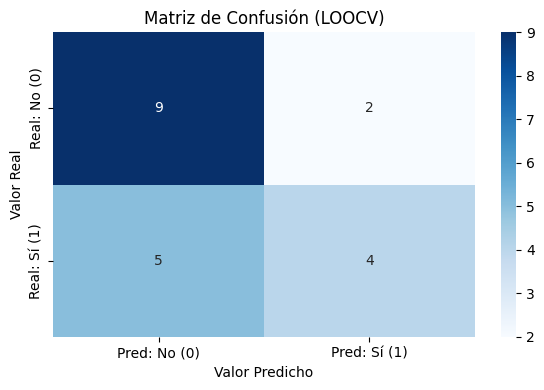


--- 🏆 IMPORTANCIA DE LAS VARIABLES (Feature Importance) ---
                                                                                                   Feature  Importance
                                                                                   efecto_sueno_sin efecto    0.128307
                                                                                                 horas_dia    0.117390
                                                                        efecto_sueno_no la usa para dormir    0.087491
                                                                                   influencia_energia_alta    0.086984
                                        definicion_respeto_Opinión y pensamiento, Cuerpo y límites físicos    0.069667
                                                                                       cambio_animo_mejora    0.054866
                                                                                     efecto_sueno_favorece

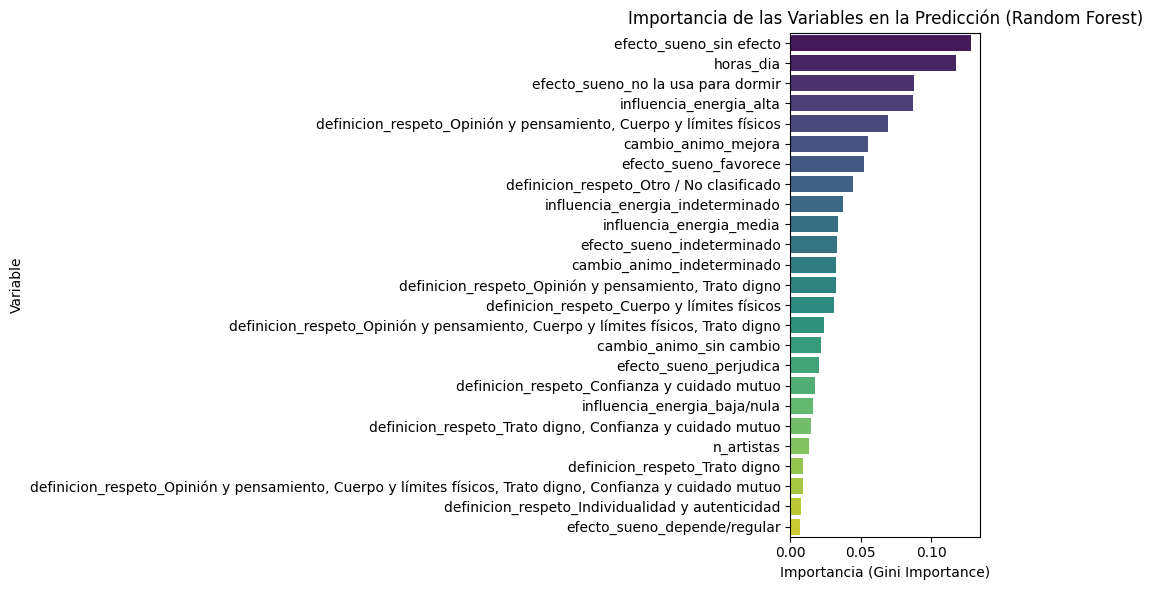

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import LeaveOneOut
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# ==============================================================================
# PASO 1: PREPARACIÓN DEL DATASET FINAL PARA ML
# ==============================================================================

# 1.1 Seleccionar solo las columnas relevantes (Target + Top Features)
cols_ml = [
    'tiene_pareja',          # TARGET
    'horas_dia',             # Numérica (Top Pearson)
    'n_artistas',            # Numérica (Top Pearson)
    'efecto_sueno',          # Categórica (Top Cramér's V)
    'definicion_respeto',    # Categórica (Top Cramér's V)
    'influencia_energia',    # Categórica (Top Cramér's V)
    'cambio_animo'           # Categórica (Top Cramér's V)
]

# Filtramos y eliminamos filas con NaN en las variables seleccionadas (por seguridad)
df_ml = df_merged[cols_ml].dropna().copy()

print(f"✅ Dataset reducido a {df_ml.shape[0]} filas y {df_ml.shape[1]} columnas para ML.")

# 1.2 Codificación de Variables
# Target: 'si' -> 1, 'no' -> 0
df_ml['tiene_pareja_num'] = df_ml['tiene_pareja'].map({'si': 1, 'no': 0})

# Features categóricas: One-Hot Encoding (Crear columnas binarias 0/1)
df_ml_encoded = pd.get_dummies(df_ml, columns=['efecto_sueno', 'definicion_respeto', 'influencia_energia', 'cambio_animo'], drop_first=False)

# Separar X (features) e y (target)
X = df_ml_encoded.drop(columns=['tiene_pareja', 'tiene_pareja_num'])
y = df_ml_encoded['tiene_pareja_num']

print(f"✅ Features finales (X): {X.shape[1]} columnas después de One-Hot Encoding.")
print(f"✅ Target (y): {y.value_counts().to_dict()}")

# ==============================================================================
# PASO 2: MODELADO CON LEAVE-ONE-OUT CROSS-VALIDATION (LOOCV)
# ==============================================================================
print("\n--- 🤖 INICIANDO ENTRENAMIENTO CON LOOCV ---")

# Inicializamos LOOCV y el Modelo (Random Forest con profundidad limitada para evitar overfitting en N=20)
loo = LeaveOneOut()
rf_model = RandomForestClassifier(n_estimators=100, max_depth=3, random_state=42, class_weight='balanced')

# Listas para guardar las predicciones reales y predichas
y_true = []
y_pred = []

# Bucle LOOCV: Entrena con 19, prueba con 1. Repite 20 veces.
for train_index, test_index in loo.split(X):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    # Entrenar
    rf_model.fit(X_train, y_train)

    # Predecir
    pred = rf_model.predict(X_test)

    y_true.extend(y_test)
    y_pred.extend(pred)

# ==============================================================================
# PASO 3: EVALUACIÓN DE RESULTADOS
# ==============================================================================
print("\n--- 📊 MÉTRICAS DE EVALUACIÓN (LOOCV) ---")
print(f"Accuracy (Exactitud):  {accuracy_score(y_true, y_pred):.2f}")
print(f"Precision:             {precision_score(y_true, y_pred, zero_division=0):.2f}")
print(f"Recall (Sensibilidad): {recall_score(y_true, y_pred, zero_division=0):.2f}")
print(f"F1-Score:              {f1_score(y_true, y_pred, zero_division=0):.2f}")

print("\n📋 Reporte de Clasificación:")
print(classification_report(y_true, y_pred, target_names=['No tiene pareja (0)', 'Sí tiene pareja (1)'], zero_division=0))

# Matriz de Confusión Visual
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred: No (0)', 'Pred: Sí (1)'],
            yticklabels=['Real: No (0)', 'Real: Sí (1)'])
plt.title('Matriz de Confusión (LOOCV)')
plt.ylabel('Valor Real')
plt.xlabel('Valor Predicho')
plt.tight_layout()
plt.show()

# ==============================================================================
# PASO 4: IMPORTANCIA DE LAS FEATURES
# ==============================================================================
# Entrenamos el modelo con TODOS los datos una vez más para extraer la importancia global
rf_model.fit(X, y)

importances = rf_model.feature_importances_
feature_names = X.columns

# Crear un DataFrame para ordenar y graficar
feat_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

print("\n--- 🏆 IMPORTANCIA DE LAS VARIABLES (Feature Importance) ---")
print(feat_imp_df.to_string(index=False))

# Gráfico de Importancia
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette='viridis')
plt.title('Importancia de las Variables en la Predicción (Random Forest)')
plt.xlabel('Importancia (Gini Importance)')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()

## Clusters

In [6]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from scipy.stats import chi2_contingency, f_oneway
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================================
# PASO 1: Seleccionar variables para clustering
# ============================================================================
# Variables que representan PERSONALIDAD y VALORES (no gustos musicales superficiales)
features_clustering = [
    'horas_dia',                    # Intensidad de uso de música
    'edad_primera_relacion',        # Experiencia relacional
    'efecto_sueno',                 # Regulación emocional (sueño)
    'influencia_energia',           # Regulación emocional (energía)
    'cambio_animo',                 # Regulación emocional (ánimo)
    'definicion_respeto',           # Valores relacionales
    'cualidad_valorada',            # Qué valora en pareja
    'resolucion_desacuerdos',       # Estilo de comunicación
    'demostracion_carino'           # Lenguajes del amor
]

# Filtrar solo las columnas que existen en tu dataset
features_existentes = [f for f in features_clustering if f in df_merged.columns]
print(f"✓ Features seleccionadas para clustering: {len(features_existentes)}")
print(f"  {features_existentes}")

# ============================================================================
# PASO 2: Preprocesamiento
# ============================================================================
df_cluster = df_merged[features_existentes + ['cuenta', 'genero', 'tiene_pareja']].copy()

# Eliminar filas con NaN en las features
df_cluster = df_cluster.dropna(subset=features_existentes)
print(f"\n✓ Dataset para clustering: {df_cluster.shape[0]} muestras")

# Codificar variables categóricas
le_dict = {}
for col in features_existentes:
    if df_cluster[col].dtype == 'object':
        le = LabelEncoder()
        df_cluster[f'{col}_encoded'] = le.fit_transform(df_cluster[col].astype(str))
        le_dict[col] = le
    else:
        df_cluster[f'{col}_encoded'] = df_cluster[col]

# Lista de columnas encoded
encoded_cols = [f'{col}_encoded' for col in features_existentes]

# Estandarizar
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_cluster[encoded_cols])

print(f"✓ Features preparadas y estandarizadas")

✓ Features seleccionadas para clustering: 9
  ['horas_dia', 'edad_primera_relacion', 'efecto_sueno', 'influencia_energia', 'cambio_animo', 'definicion_respeto', 'cualidad_valorada', 'resolucion_desacuerdos', 'demostracion_carino']

✓ Dataset para clustering: 20 muestras
✓ Features preparadas y estandarizadas



--- 🔍 ANÁLISIS DE NÚMERO ÓPTIMO DE CLUSTERS ---
K=2: Silhouette=0.155, Calinski-Harabasz=4.8, Davies-Bouldin=1.870
K=3: Silhouette=0.138, Calinski-Harabasz=4.5, Davies-Bouldin=1.676
K=4: Silhouette=0.160, Calinski-Harabasz=4.3, Davies-Bouldin=1.465
K=5: Silhouette=0.126, Calinski-Harabasz=3.9, Davies-Bouldin=1.387
K=6: Silhouette=0.146, Calinski-Harabasz=4.1, Davies-Bouldin=1.349
K=7: Silhouette=0.168, Calinski-Harabasz=3.9, Davies-Bouldin=1.157
K=8: Silhouette=0.206, Calinski-Harabasz=4.3, Davies-Bouldin=0.964
K=9: Silhouette=0.171, Calinski-Harabasz=4.1, Davies-Bouldin=0.870
K=10: Silhouette=0.179, Calinski-Harabasz=4.4, Davies-Bouldin=0.806
K=11: Silhouette=0.198, Calinski-Harabasz=4.9, Davies-Bouldin=0.735
K=12: Silhouette=0.184, Calinski-Harabasz=5.0, Davies-Bouldin=0.663
K=13: Silhouette=0.165, Calinski-Harabasz=5.0, Davies-Bouldin=0.628
K=14: Silhouette=0.171, Calinski-Harabasz=5.9, Davies-Bouldin=0.533


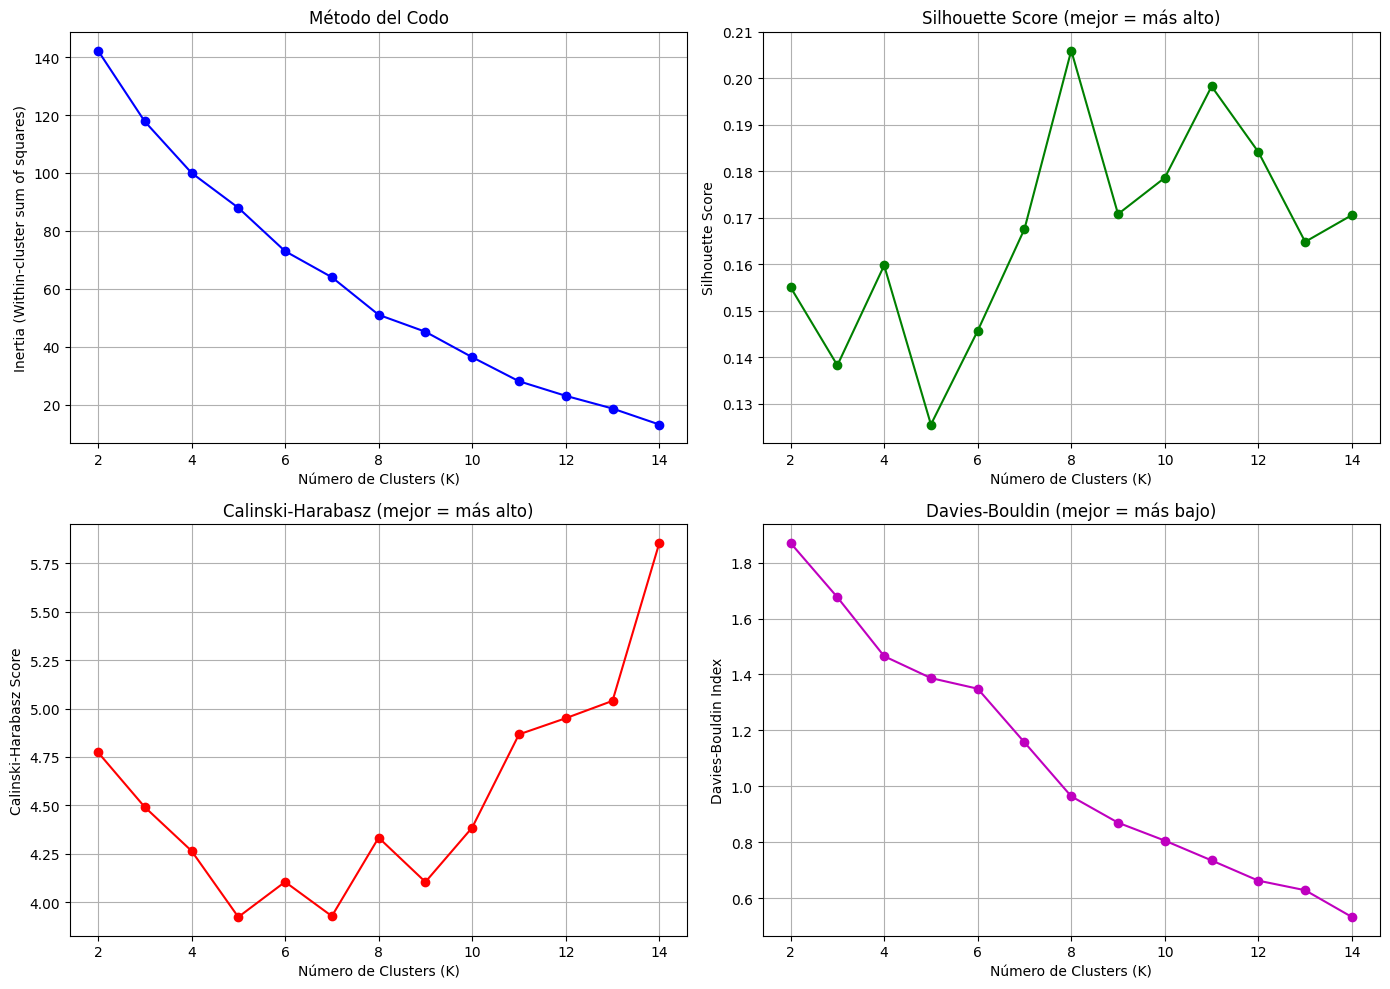


✓ K óptimo seleccionado: 8 (Silhouette=0.206)

✓ Clustering completado con 8 clusters
  Distribución: {0: 4, 1: 4, 2: 2, 3: 2, 4: 3, 5: 2, 6: 2, 7: 1}


In [8]:
# ============================================================================
# PASO 3: Determinar número óptimo de clusters
# ============================================================================
print("\n--- 🔍 ANÁLISIS DE NÚMERO ÓPTIMO DE CLUSTERS ---")

inertia = []
silhouette_scores = []
calinski_scores = []
davies_bouldin_scores = []

K_range = range(2, 15)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))
    calinski_scores.append(calinski_harabasz_score(X_scaled, labels))
    davies_bouldin_scores.append(davies_bouldin_score(X_scaled, labels))

    print(f"K={k}: Silhouette={silhouette_scores[-1]:.3f}, "
          f"Calinski-Harabasz={calinski_scores[-1]:.1f}, "
          f"Davies-Bouldin={davies_bouldin_scores[-1]:.3f}")

# Visualización
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Elbow method
axes[0, 0].plot(K_range, inertia, 'bo-')
axes[0, 0].set_xlabel('Número de Clusters (K)')
axes[0, 0].set_ylabel('Inertia (Within-cluster sum of squares)')
axes[0, 0].set_title('Método del Codo')
axes[0, 0].grid(True)

# Silhouette score
axes[0, 1].plot(K_range, silhouette_scores, 'go-')
axes[0, 1].set_xlabel('Número de Clusters (K)')
axes[0, 1].set_ylabel('Silhouette Score')
axes[0, 1].set_title('Silhouette Score (mejor = más alto)')
axes[0, 1].grid(True)

# Calinski-Harabasz
axes[1, 0].plot(K_range, calinski_scores, 'ro-')
axes[1, 0].set_xlabel('Número de Clusters (K)')
axes[1, 0].set_ylabel('Calinski-Harabasz Score')
axes[1, 0].set_title('Calinski-Harabasz (mejor = más alto)')
axes[1, 0].grid(True)

# Davies-Bouldin
axes[1, 1].plot(K_range, davies_bouldin_scores, 'mo-')
axes[1, 1].set_xlabel('Número de Clusters (K)')
axes[1, 1].set_ylabel('Davies-Bouldin Index')
axes[1, 1].set_title('Davies-Bouldin (mejor = más bajo)')
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

# Seleccionar K óptimo (basado en silhouette)
optimal_k = K_range[np.argmax(silhouette_scores)]
print(f"\n✓ K óptimo seleccionado: {optimal_k} (Silhouette={max(silhouette_scores):.3f})")

# ============================================================================
# PASO 4: Aplicar clustering con K óptimo
# ============================================================================
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df_cluster['cluster'] = kmeans_final.fit_predict(X_scaled)

print(f"\n✓ Clustering completado con {optimal_k} clusters")
print(f"  Distribución: {df_cluster['cluster'].value_counts().sort_index().to_dict()}")


--- 📊 CARACTERIZACIÓN DE CLUSTERS ---

HORAS_DIA:
  ANOVA: F=1.68, p=0.2063 ✗ No significativo
    Cluster 0: media=4.00
    Cluster 1: media=4.38
    Cluster 2: media=9.50
    Cluster 3: media=7.50
    Cluster 4: media=4.00
    Cluster 5: media=1.50
    Cluster 6: media=1.00
    Cluster 7: media=5.00

EDAD_PRIMERA_RELACION:
  ANOVA: F=4.19, p=0.0147 ✓ SIGNIFICATIVO
    Cluster 0: media=15.75
    Cluster 1: media=16.00
    Cluster 2: media=0.00
    Cluster 3: media=12.00
    Cluster 4: media=15.33
    Cluster 5: media=16.00
    Cluster 6: media=7.00
    Cluster 7: media=15.00

EFECTO_SUENO:
  Chi-cuadrado: χ²=36.03, p=0.4201 ✗ No significativo
    Cluster 0: más frecuente='sin efecto' (3/4)
    Cluster 1: más frecuente='indeterminado' (1/4)
    Cluster 2: más frecuente='favorece' (2/2)
    Cluster 3: más frecuente='favorece' (1/2)
    Cluster 4: más frecuente='sin efecto' (1/3)
    Cluster 5: más frecuente='depende/regular' (1/2)
    Cluster 6: más frecuente='sin efecto' (2/2)
    Clu

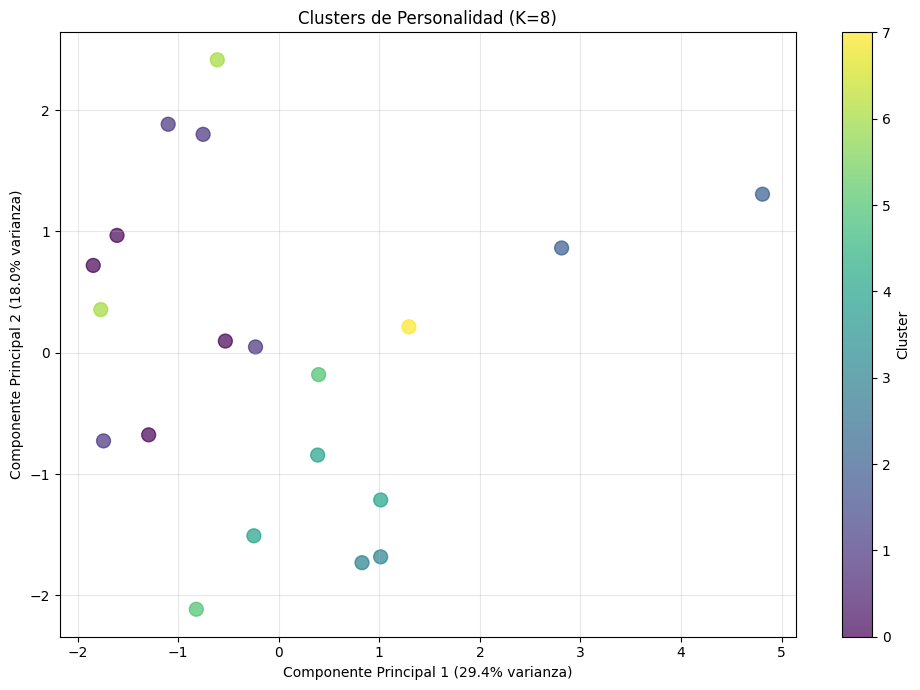

In [9]:
# ============================================================================
# PASO 5: Análisis de qué caracteriza a cada cluster
# ============================================================================
print("\n--- 📊 CARACTERIZACIÓN DE CLUSTERS ---")

# Para cada feature, calcular la media/mediana por cluster
for feature in features_existentes:
    print(f"\n{feature.upper()}:")

    if feature in ['horas_dia', 'edad_primera_relacion']:
        # Variables numéricas: ANOVA para ver si hay diferencias significativas
        groups = [df_cluster[df_cluster['cluster'] == k][feature].values
                  for k in range(optimal_k)]
        f_stat, p_value = f_oneway(*groups)

        print(f"  ANOVA: F={f_stat:.2f}, p={p_value:.4f} {'✓ SIGNIFICATIVO' if p_value < 0.05 else '✗ No significativo'}")

        for k in range(optimal_k):
            mean_val = df_cluster[df_cluster['cluster'] == k][feature].mean()
            print(f"    Cluster {k}: media={mean_val:.2f}")
    else:
        # Variables categóricas: Chi-cuadrado
        contingency = pd.crosstab(df_cluster['cluster'], df_cluster[feature])
        chi2, p_value, dof, expected = chi2_contingency(contingency)

        print(f"  Chi-cuadrado: χ²={chi2:.2f}, p={p_value:.4f} {'✓ SIGNIFICATIVO' if p_value < 0.05 else '✗ No significativo'}")

        # Mostrar distribución
        for k in range(optimal_k):
            cluster_data = df_cluster[df_cluster['cluster'] == k][feature]
            top_category = cluster_data.value_counts().index[0] if len(cluster_data) > 0 else 'N/A'
            top_count = cluster_data.value_counts().iloc[0] if len(cluster_data) > 0 else 0
            print(f"    Cluster {k}: más frecuente='{top_category}' ({top_count}/{len(cluster_data)})")

# ============================================================================
# PASO 6: Visualización de clusters en 2D (PCA)
# ============================================================================
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df_cluster['cluster'],
                      cmap='viridis', s=100, alpha=0.7)
plt.xlabel(f'Componente Principal 1 ({pca.explained_variance_ratio_[0]:.1%} varianza)')
plt.ylabel(f'Componente Principal 2 ({pca.explained_variance_ratio_[1]:.1%} varianza)')
plt.title(f'Clusters de Personalidad (K={optimal_k})')
plt.colorbar(scatter, label='Cluster')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Genero

In [11]:
import pandas as pd
import numpy as np

# ==============================================================================
# PASO 1: Cargar el dataset externo "respuestas"
# (Ajusta 'respuestas.csv' al nombre real de tu archivo, ej. 'respuestas.xlsx')
# ==============================================================================
try:
    df_respuestas = pd.read_csv('respuestas.csv')
except FileNotFoundError:
    df_respuestas = pd.read_excel('respuestas.xlsx')

# ==============================================================================
# PASO 2: Extraer solo las columnas por su índice (0-index)
# Índice 1 = Columna 2 (Clave de unión, ej. número de cuenta o correo)
# Índice 2 = Columna 3 (Género del encuestado)
# ==============================================================================
df_genero = df_respuestas.iloc[:, [2, 3]].copy()

# Renombramos las columnas para que sean claras y fáciles de manejar
df_genero.columns = ['clave_unica', 'genero']

# ==============================================================================
# PASO 3: Limpiar la clave de unión para garantizar que coincida con df_amor
# ==============================================================================
# Convertimos a string y extraemos solo los 9 dígitos del número de cuenta
# (esto evita fallos si hay espacios, ceros a la izquierda o texto extra)
df_genero['clave_unica'] = df_genero['clave_unica'].astype(str).str.extract(r'(\d{9})')

# Eliminamos filas donde no se pudo extraer una cuenta válida (ej. encabezados o filas vacías)
df_genero = df_genero.dropna(subset=['clave_unica'])

# ==============================================================================
# PASO 4: Preparar df_amor para la unión (Merge)
# ==============================================================================
# Aseguramos que la columna de unión en tu dataset original también esté limpia
# (Asumiendo que tu columna de cuenta en df_amor se llama 'cuenta' o 'No. Cuenta')
col_cuenta_amor = 'cuenta' if 'cuenta' in df_amor.columns else 'No. Cuenta'
df_amor['cuenta_limpia'] = df_amor[col_cuenta_amor].astype(str).str.extract(r'(\d{9})')

# ==============================================================================
# PASO 5: Realizar el Merge (Unión)
# ==============================================================================
# Usamos 'left' para conservar TODOS los registros de df_amor,
# y agregar el género solo donde haya coincidencia.
df_amor_con_genero = pd.merge(
    df_amor,
    df_genero,
    left_on='cuenta_limpia',
    right_on='clave_unica',
    how='left'
)

# ==============================================================================
# PASO 6: Limpieza final y verificación
# ==============================================================================
# Eliminamos las columnas temporales de claves que ya no necesitamos
df_amor_con_genero = df_amor_con_genero.drop(columns=['cuenta_limpia', 'clave_unica'])

# Verificamos que la asignación se haya realizado correctamente
print("✅ Género asignado exitosamente desde el dataset original.")
print("\n📊 Distribución del género en el dataset unificado:")
print(df_amor_con_genero['genero'].value_counts(dropna=False))

print("\n🔍 Muestra de las primeras filas con las nuevas columnas:")
cols_a_mostrar = [col_cuenta_amor, 'genero', 'tiene_pareja']
cols_existentes = [c for c in cols_a_mostrar if c in df_amor_con_genero.columns]
display(df_amor_con_genero[cols_existentes].head())

✅ Género asignado exitosamente desde el dataset original.

📊 Distribución del género en el dataset unificado:
genero
Masculino     9
Masculino     4
Femenino      3
Hombre        1
Femenino.     1
Mujer         1
masculino     1
Femenino      1
Name: count, dtype: int64

🔍 Muestra de las primeras filas con las nuevas columnas:


,cuenta,genero,tiene_pareja
0,321188065,Masculino,si
1,424059594,Masculino,no
2,423085822,Hombre,si
3,424000455,Femenino,no
4,424144407,Femenino,si


In [12]:
# ==============================================================================
# ESTANDARIZACIÓN DE LA VARIABLE 'genero'
# ==============================================================================

# 1. Crear una versión en minúsculas y sin espacios para facilitar el mapeo
df_amor_con_genero['genero_temp'] = df_amor_con_genero['genero'].astype(str).str.lower().str.strip()

# 2. Función de mapeo para unificar categorías
def estandarizar_genero(valor):
    if valor in ['masculino', 'hombre']:
        return 'Masculino'
    elif valor in ['femenino', 'mujer', 'femenino.']:
        return 'Femenino'
    else:
        return 'No especificado' # Por si aparece alguna otra variación rara

# 3. Aplicar la función y reemplazar la columna original
df_amor_con_genero['genero'] = df_amor_con_genero['genero_temp'].apply(estandarizar_genero)

# 4. Eliminar la columna temporal
df_amor_con_genero = df_amor_con_genero.drop(columns=['genero_temp'])

# 5. Verificación final
print("✅ Variable 'genero' estandarizada exitosamente.")
print("\n📊 Distribución final y limpia del género:")
print(df_amor_con_genero['genero'].value_counts(dropna=False))

# Opcional: Ver visualmente que no queden rarezas
print("\n🔍 Valores únicos finales:", df_amor_con_genero['genero'].unique())

✅ Variable 'genero' estandarizada exitosamente.

📊 Distribución final y limpia del género:
genero
Masculino    15
Femenino      6
Name: count, dtype: int64

🔍 Valores únicos finales: ['Masculino' 'Femenino']
